<a href="https://colab.research.google.com/github/abdul-rafey7016/24I-2589/blob/main/LAB11/i242589_lab11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
df=pd.read_csv("Tweets.csv")
print(df.shape)
print(df.head())

(14640, 15)
             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin                 NaN              0   
1                   

In [5]:
text=df['text']
text

,text
0,@VirginAmerica What @dhepburn said.
1,@VirginAmerica plus you've added commercials t...
2,@VirginAmerica I didn't today... Must mean I n...
3,@VirginAmerica it's really aggressive to blast...
4,@VirginAmerica and it's a really big bad thing...
...,...
14635,@AmericanAir thank you we got on a different f...
14636,@AmericanAir leaving over 20 minutes Late Flig...
14637,@AmericanAir Please bring American Airlines to...
14638,"@AmericanAir you have my money, you change my ..."


In [12]:
import re
import nltk
from nltk.tokenize import TweetTokenizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

nltk.download('stopwords')
from nltk.corpus import stopwords

# Instantiate a specialized social media tokenizer (TweetTokenizer)
tt = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
stop_words = set(stopwords.words('english'))

def preprocess_tweet(text):
    # 1. Lowercase
    text = text.lower()
    # 2. Remove URLs
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    # 3. Handle Hashtags (remove the '#' but keep the word)
    text = re.sub(r'#(\w+)', r'\1', text)
    # 4. Tokenize
    tokens = tt.tokenize(text)
    # 5. Remove non-alphanumeric tokens
    cleaned_tokens = [token for token in tokens if token.isalnum()]
    return ' '.join(cleaned_tokens)

def preprocess_tweet_without_stopwords(text):
    # Since the input is already preprocessed and joined by spaces, we can split it to get the tokens
    tokens = text.split()
    # Remove stopwords
    cleaned_tokens = [token for token in tokens if token not in stop_words]
    return ' '.join(cleaned_tokens)

# Apply preprocessing to our tweet text
df['cleaned_text_with_stopwords'] = df['text'].apply(preprocess_tweet)
df['cleaned_text'] = df['cleaned_text_with_stopwords'].apply(preprocess_tweet_without_stopwords)
display(df[['text', 'cleaned_text_with_stopwords', 'cleaned_text']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,text,cleaned_text_with_stopwords,cleaned_text
0,@VirginAmerica What @dhepburn said.,what said,said
1,@VirginAmerica plus you've added commercials t...,plus added commercials to the experience tacky,plus added commercials experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,i today must mean i need to take another trip,today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive to blast obnoxious entertain...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,and a really big bad thing about it,really big bad thing


In [16]:
# Prepare data for model training
X1 = df['cleaned_text']
X2 = df['cleaned_text_with_stopwords']
y1 = df['airline_sentiment']

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y1, test_size=0.2, random_state=42, stratify=y1)

# TF-IDF Vectorization (Without Stopwords)
vectorizer1 = TfidfVectorizer(max_features=5000)
X1_train_tfidf = vectorizer1.fit_transform(X1_train)
X1_test_tfidf = vectorizer1.transform(X1_test)

# Train a Logistic Regression model
model1 = LogisticRegression(max_iter=1000)
model1.fit(X1_train_tfidf, y1_train)

# TF-IDF Vectorization (With Stopwords)
vectorizer2 = TfidfVectorizer(max_features=5000)
X2_train_tfidf = vectorizer2.fit_transform(X2_train)
X2_test_tfidf = vectorizer2.transform(X2_test) # Corrected to use vectorizer2

# Train a Logistic Regression model
model2 = LogisticRegression(max_iter=1000)
model2.fit(X2_train_tfidf, y2_train)

print('Evaluation without stop words')
# Evaluate the model
y1_pred = model1.predict(X1_test_tfidf)
print(f"Accuracy: {accuracy_score(y1_test, y1_pred):.4f}\n")
print(classification_report(y1_test, y1_pred))

print('Evaluation with stop words')
# Evaluate the model
y2_pred = model2.predict(X2_test_tfidf)
print(f"Accuracy: {accuracy_score(y2_test, y2_pred):.4f}\n")
print(classification_report(y2_test, y2_pred))

Evaluation without stop words
Accuracy: 0.7760

              precision    recall  f1-score   support

    negative       0.79      0.94      0.86      1835
     neutral       0.65      0.45      0.53       620
    positive       0.82      0.56      0.66       473

    accuracy                           0.78      2928
   macro avg       0.75      0.65      0.69      2928
weighted avg       0.77      0.78      0.76      2928

Evaluation with stop words
Accuracy: 0.7883

              precision    recall  f1-score   support

    negative       0.82      0.94      0.87      1835
     neutral       0.66      0.52      0.58       620
    positive       0.81      0.55      0.66       473

    accuracy                           0.79      2928
   macro avg       0.76      0.67      0.70      2928
weighted avg       0.78      0.79      0.78      2928



In [17]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer
from collections import Counter

nltk.download('wordnet')
nltk.download('omw-1.4')

# Extract unique vocabulary words from our cleaned text column
all_words = " ".join(df['cleaned_text'].dropna()).split()
vocab = sorted(list(set(all_words)))
vocab_size_initial = len(vocab)

# Initialize stemmer and lemmatizer
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Apply both techniques to the vocabulary
stemmed_vocab = {}
lemmatized_vocab = {}
disagreement_examples = []

for word in vocab:
    stem = stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos='v') # using verb POS for robust base mapping
    stemmed_vocab[word] = stem
    lemmatized_vocab[word] = lemma

    # Track disagreements
    if stem != lemma:
        disagreement_examples.append((word, stem, lemma))

unique_stems = set(stemmed_vocab.values())
unique_lemmas = set(lemmatized_vocab.values())

print(f"Initial Unique Vocabulary Size: {vocab_size_initial}")
print(f"Vocabulary Size after Stemming: {len(unique_stems)}")
print(f"Vocabulary Size after Lemmatization: {len(unique_lemmas)}\n")

print("Top 15 examples where Stemming and Lemmatization disagree / distort:")
print(f"{'Original Word':<18} | {'Stemmer (Porter)':<18} | {'Lemmatizer (WordNet)':<20}")
print("-" * 62)
for original, stem, lemma in disagreement_examples[:15]:
    print(f"{original:<18} | {stem:<18} | {lemma:<20}")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Initial Unique Vocabulary Size: 12675
Vocabulary Size after Stemming: 10018
Vocabulary Size after Lemmatization: 10980

Top 15 examples where Stemming and Lemmatization disagree / distort:
Original Word      | Stemmer (Porter)   | Lemmatizer (WordNet)
--------------------------------------------------------------
10hrs              | 10hr               | 10hrs               
10mins             | 10min              | 10mins              
10voucherwhatajoke | 10voucherwhatajok  | 10voucherwhatajoke  
145s               | 145                | 145s                
14hrs              | 14hr               | 14hrs               
1571aus            | 1571au             | 1571aus             
15hours            | 15hour             | 15hours             
15mins             | 15min              | 15mins              
15minutes          | 15minut            | 15minutes           
1800flowers        | 1800flower         | 1800flowers         
18hrs              | 18hr               | 18hrs        

In [20]:
import re
import pandas as pd
from nltk.tokenize import TweetTokenizer

tt = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)

# Prepare containers for metrics
metrics = []

# Stage 0: Original Raw Data
raw_toks = [text.split() for text in df['text'].fillna('')]
raw_vocab = set(word for doc in raw_toks for word in doc)
metrics.append({
    'Stage': '0. Raw Data',
    'Vocab Size': len(raw_vocab),
    'Avg Tweet Length (words)': sum(len(doc) for doc in raw_toks) / len(df),
    'Empty Tweets Count': sum(1 for doc in raw_toks if len(doc) == 0)
})

# Stage 1: After structural cleaning (lowercasing, handles/URLs removed, punctuation stripped)
stage1_toks = [text.split() for text in df['cleaned_text_with_stopwords'].fillna('')]
stage1_vocab = set(word for doc in stage1_toks for word in doc)
metrics.append({
    'Stage': '1. Structural Clean (no URLs/handles/punc)',
    'Vocab Size': len(stage1_vocab),
    'Avg Tweet Length (words)': sum(len(doc) for doc in stage1_toks) / len(df),
    'Empty Tweets Count': sum(1 for doc in stage1_toks if len(doc) == 0)
})

# Stage 2: After Stopword Removal
stage2_toks = [text.split() for text in df['cleaned_text'].fillna('')]
stage2_vocab = set(word for doc in stage2_toks for word in doc)
metrics.append({
    'Stage': '2. Final Clean (Stopwords Removed)',
    'Vocab Size': len(stage2_vocab),
    'Avg Tweet Length (words)': sum(len(doc) for doc in stage2_toks) / len(df),
    'Empty Tweets Count': sum(1 for doc in stage2_toks if len(doc) == 0)
})

# Create a DataFrame to display the metrics side-by-side
metrics_df = pd.DataFrame(metrics)
display(metrics_df)

,Stage,Vocab Size,Avg Tweet Length (words),Empty Tweets Count
0,0. Raw Data,30105,17.653415,0
1,1. Structural Clean (no URLs/handles/punc),12816,15.882104,1
2,2. Final Clean (Stopwords Removed),12675,8.825546,31


In [21]:
from collections import Counter
import numpy as np

# 5. Most frequent words in raw data
raw_words = [word.lower() for doc in raw_toks for word in doc]
raw_counts = Counter(raw_words)
print("Top 15 Raw Words:")
for word, count in raw_counts.most_common(15):
    print(f"{word}: {count}")


Top 15 Raw Words:
to: 8590
the: 6034
i: 5351
a: 4461
for: 3964
@united: 3760
and: 3693
on: 3652
you: 3607
my: 3272
flight: 3217
@usairways: 2938
@americanair: 2885
is: 2770
in: 2446


In [22]:
# 6. Find words that truly separate the two groups (using tf-idf or conditional probabilities)
# Let's use Log Odds Ratio with Dirichlet Prior or simple ratio of normalized frequencies
neg_tweets = df[df['airline_sentiment'] == 'negative']['cleaned_text_with_stopwords']
pos_tweets = df[df['airline_sentiment'] == 'positive']['cleaned_text_with_stopwords']

neg_words = [w for doc in neg_tweets.str.split() for w in doc]
pos_words = [w for doc in pos_tweets.str.split() for w in doc]

neg_counts = Counter(neg_words)
pos_counts = Counter(pos_words)

total_neg = sum(neg_counts.values())
total_pos = sum(pos_counts.values())

# Calculate a score: (P(word | positive) + epsilon) / (P(word | negative) + epsilon)
# High score -> Positive-specific; Low score -> Negative-specific
all_vocab = set(neg_counts.keys()).union(set(pos_counts.keys()))
word_scores = []

for w in all_vocab:
    p_pos = (pos_counts[w] + 1) / (total_pos + 1000)
    p_neg = (neg_counts[w] + 1) / (total_neg + 1000)
    ratio = p_pos / p_neg
    word_scores.append((w, ratio, pos_counts[w], neg_counts[w]))

# Sort by ratio to find positive-separating and negative-separating words
word_scores.sort(key=lambda x: x[1], reverse=True)

print("Top 15 Words Separating POSITIVE (Highest ratio of Pos/Neg density):")
for w, r, pc, nc in word_scores[:15]:
    print(f"{w:<15} | Ratio: {r:.2f} (Pos count: {pc}, Neg count: {nc})")

print("\nTop 15 Words Separating NEGATIVE (Lowest ratio of Pos/Neg density):")
for w, r, pc, nc in word_scores[-15:]:
    print(f"{w:<15} | Ratio: {r:.4f} (Pos count: {pc}, Neg count: {nc})")


Top 15 Words Separating POSITIVE (Highest ratio of Pos/Neg density):
smooth          | Ratio: 54.96 (Pos count: 9, Neg count: 0)
passbook        | Ratio: 46.72 (Pos count: 16, Neg count: 1)
deals           | Ratio: 43.97 (Pos count: 7, Neg count: 0)
exceptional     | Ratio: 43.97 (Pos count: 7, Neg count: 0)
comfortable     | Ratio: 43.97 (Pos count: 7, Neg count: 0)
favorite        | Ratio: 41.22 (Pos count: 14, Neg count: 1)
bluemanity      | Ratio: 38.47 (Pos count: 6, Neg count: 0)
rock            | Ratio: 38.47 (Pos count: 27, Neg count: 3)
terry           | Ratio: 38.47 (Pos count: 6, Neg count: 0)
aww             | Ratio: 38.47 (Pos count: 6, Neg count: 0)
pleasure        | Ratio: 38.47 (Pos count: 6, Neg count: 0)
kudos           | Ratio: 37.10 (Pos count: 26, Neg count: 3)
outstanding     | Ratio: 35.72 (Pos count: 12, Neg count: 1)
fantastic       | Ratio: 34.81 (Pos count: 18, Neg count: 2)
beautiful       | Ratio: 32.98 (Pos count: 11, Neg count: 1)

Top 15 Words Separating

In [23]:
# 7. Find phrases pointing to operational problems (Bigrams)
from nltk.util import ngrams

neg_bigrams = []
for doc in neg_tweets.str.split():
    neg_bigrams.extend(list(ngrams(doc, 2)))

bigram_counts = Counter(neg_bigrams)
print("Top Negative Bigrams:")
for bg, count in bigram_counts.most_common(20):
    print(f"{' '.join(bg)}: {count}")


Top Negative Bigrams:
on hold: 505
customer service: 448
cancelled flightled: 445
on the: 429
my flight: 401
to get: 368
i have: 363
to be: 275
for a: 259
trying to: 253
a flight: 248
hold for: 245
i was: 243
this is: 237
an hour: 227
for the: 221
late flight: 220
in the: 216
due to: 206
cancelled flighted: 201


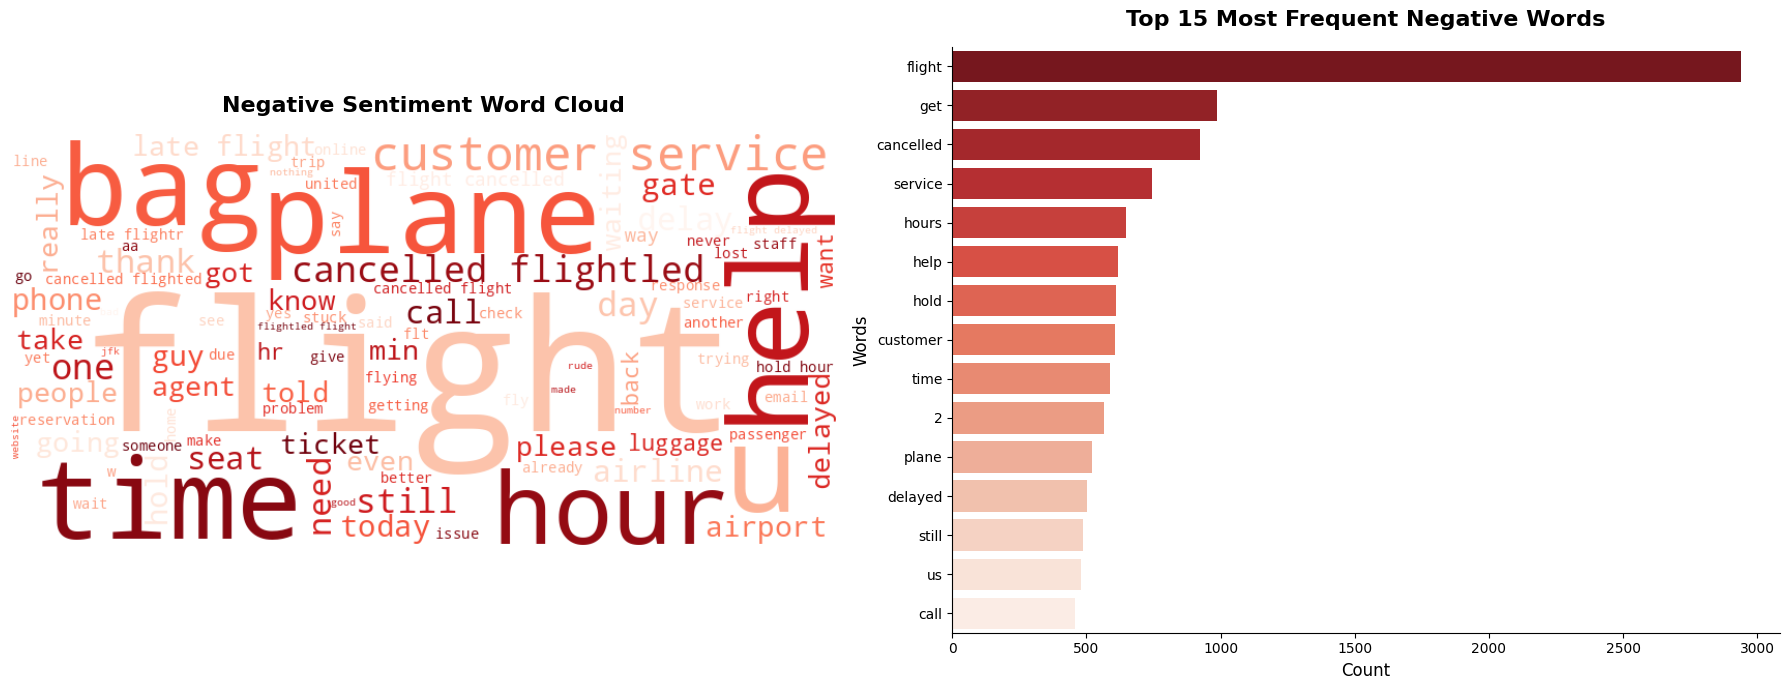

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Prepare data from Stage 2 (Stopwords removed) for negative tweets
neg_clean_text = " ".join(df[df['airline_sentiment'] == 'negative']['cleaned_text'].dropna())

# 1. Generate Word Cloud
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='Reds', max_words=100).generate(neg_clean_text)

# 2. Extract Top 15 Negative Words for Bar Chart
neg_words_clean = neg_clean_text.split()
neg_clean_counts = Counter(neg_words_clean)
top_15_neg = neg_clean_counts.most_common(15)
words, counts = zip(*top_15_neg)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left Plot: Word Cloud
axes[0].imshow(wordcloud, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Negative Sentiment Word Cloud', fontsize=16, fontweight='bold', pad=15)

# Right Plot: Bar Chart
sns.barplot(x=list(counts), y=list(words), ax=axes[1], palette='Reds_r', hue=list(words), legend=False)
axes[1].set_title('Top 15 Most Frequent Negative Words', fontsize=16, fontweight='bold', pad=15)
axes[1].set_xlabel('Count', fontsize=12)
axes[1].set_ylabel('Words', fontsize=12)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [25]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pandas as pd
import numpy as np

nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()

# Define mapping helper from continuous VADER score to 3 classes
def get_vader_label(text):
    scores = sia.polarity_scores(text)
    compound = scores['compound']
    if compound >= 0.05:
        return 'positive'
    elif compound <= -0.05:
        return 'negative'
    else:
        return 'neutral'

# Score all raw tweets
df['vader_sentiment'] = df['text'].apply(get_vader_label)

print("=== Overall VADER vs. Human Labels Performance ===")
print(f"Overall Accuracy: {accuracy_score(df['airline_sentiment'], df['vader_sentiment']):.4f}\n")
print(classification_report(df['airline_sentiment'], df['vader_sentiment']))

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


=== Overall VADER vs. Human Labels Performance ===
Overall Accuracy: 0.5429

              precision    recall  f1-score   support

    negative       0.90      0.50      0.64      9178
     neutral       0.38      0.43      0.41      3099
    positive       0.34      0.87      0.49      2363

    accuracy                           0.54     14640
   macro avg       0.54      0.60      0.51     14640
weighted avg       0.70      0.54      0.57     14640



In [26]:
# 10. Analyze systematic disagreements (Sarcasm, Negation, Domain words)
# We look for extreme disagreements: e.g. Human='negative' but VADER='positive'
extreme_disagreements = df[(df['airline_sentiment'] == 'negative') & (df['vader_sentiment'] == 'positive')]

# Let's inspect a few to identify the main causes:
print("Examples of Human='negative' but VADER='positive':")
for idx, row in extreme_disagreements[['text', 'vader_sentiment']].head(10).iterrows():
    print(f"- {row['text']}")

Examples of Human='negative' but VADER='positive':
- @VirginAmerica  I flew from NYC to SFO last week and couldn't fully sit in my seat due to two large gentleman on either side of me. HELP!
- @VirginAmerica you guys messed up my seating.. I reserved seating with my friends and you guys gave my seat away ... 😡 I want free internet
- @VirginAmerica amazing to me that we can't get any cold air from the vents. #VX358 #noair #worstflightever #roasted #SFOtoBOS
- @VirginAmerica help, left expensive headphones on flight 89 IAD to LAX today. Seat 2A. No one answering L&amp;F number at LAX!
- @VirginAmerica Your chat support is not working on your site: http://t.co/vhp2GtDWPk
- @VirginAmerica Hey, first time flyer next week - excited! But I'm having a hard time getting my flights added to my Elevate account. Help?
- @VirginAmerica what is going on with customer service? Is there anyway to speak to a human asap? Thank you.
- @VirginAmerica why can't you supp the biz traveler like @SouthwestAir 

In [27]:
# 11. Run three custom adversarial tweets designed to fool the lexicon tool
custom_tweets = [
    "Thanks for leaving my bags in Chicago, great service!", # Sarcasm
    "This was not a terrible flight at all, actually.",      # Double negation / Syntactic complexity
    "My flight was delayed and then cancelled.",            # Domain terms ('delayed', 'cancelled' might be neutral in general lexicons)
]

print("=== Custom Adversarial Test Cases ===")
for ct in custom_tweets:
    scores = sia.polarity_scores(ct)
    pred_label = 'positive' if scores['compound'] >= 0.05 else ('negative' if scores['compound'] <= -0.05 else 'neutral')
    print(f"Tweet: \"{ct}\"\nVADER Scores: {scores} -> Class: {pred_label}\n")

=== Custom Adversarial Test Cases ===
Tweet: "Thanks for leaving my bags in Chicago, great service!"
VADER Scores: {'neg': 0.0, 'neu': 0.49, 'pos': 0.51, 'compound': 0.807} -> Class: positive

Tweet: "This was not a terrible flight at all, actually."
VADER Scores: {'neg': 0.0, 'neu': 0.733, 'pos': 0.267, 'compound': 0.3724} -> Class: positive

Tweet: "My flight was delayed and then cancelled."
VADER Scores: {'neg': 0.438, 'neu': 0.562, 'pos': 0.0, 'compound': -0.4404} -> Class: negative



In [28]:
# 12. Evaluate how results change when filtering for high-confidence ground truth (confidence == 1.0)
high_conf_df = df[df['airline_sentiment_confidence'] == 1.0]

print("=== VADER vs. High-Confidence Human Labels Only ===")
print(f"Filtered Data Shape: {high_conf_df.shape}")
print(f"Filtered Accuracy: {accuracy_score(high_conf_df['airline_sentiment'], high_conf_df['vader_sentiment']):.4f}\n")
print(classification_report(high_conf_df['airline_sentiment'], high_conf_df['vader_sentiment']))

=== VADER vs. High-Confidence Human Labels Only ===
Filtered Data Shape: (10445, 18)
Filtered Accuracy: 0.5865

              precision    recall  f1-score   support

    negative       0.94      0.54      0.69      7382
     neutral       0.33      0.48      0.39      1548
    positive       0.35      0.92      0.50      1515

    accuracy                           0.59     10445
   macro avg       0.54      0.65      0.53     10445
weighted avg       0.77      0.59      0.62     10445



### 13. Customer Service vs. Operations Problems across Airlines
Let's analyze how complaint types (`negativereason`) are distributed across the airlines to see if one has a customer service issue and another has an operational issue.

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for negative complaints
neg_df = df[df['airline_sentiment'] == 'negative'].copy()

# Group complaint reasons into broader operational vs. customer service buckets
customer_service_reasons = ['Customer Service Issue', 'Complaints Treatment', 'Booking Problems']
operational_reasons = ['Cancelled Flight', 'Late Flight', 'Lost Luggage', 'Flight Attendant Complaints', 'Flight Booking Problems', 'Long Lines', 'Damaged Luggage']

def bucket_reason(reason):
    if reason in customer_service_reasons:
        return 'Customer Service Issue'
    elif reason in operational_reasons:
        return 'Operational Issue'
    else:
        return 'Other/Can\'t Tell'

neg_df['reason_bucket'] = neg_df['negativereason'].apply(bucket_reason)

# Pivot to compare profiles
complaint_mix = pd.crosstab(neg_df['airline'], neg_df['reason_bucket'], normalize='index') * 100
print("=== Percentage Complaint Mix per Airline ===")
display(complaint_mix.round(2))

=== Percentage Complaint Mix per Airline ===


reason_bucket,Customer Service Issue,Operational Issue,Other/Can't Tell
airline,,,
American,39.18,44.54,16.28
Delta,20.84,51.52,27.64
Southwest,32.97,43.59,23.44
US Airways,35.84,46.49,17.68
United,25.86,49.72,24.42
Virgin America,33.15,42.54,24.31


### 14. Raw Complaint Counts vs. Sentiment Share

In [30]:
# Calculate total tweets vs. share of negative sentiment
airline_shares = pd.crosstab(df['airline'], df['airline_sentiment'], normalize='index') * 100
airline_counts = pd.crosstab(df['airline'], df['airline_sentiment'])

summary_compare = airline_counts.join(airline_shares, lsuffix='_count', rsuffix='_percent')
display(summary_compare)

airline_sentiment,negative_count,neutral_count,positive_count,negative_percent,neutral_percent,positive_percent
airline,,,,,,
American,1960,463,336,71.040232,16.781443,12.178325
Delta,955,723,544,42.979298,32.538254,24.482448
Southwest,1186,664,570,49.008264,27.438017,23.553719
US Airways,2263,381,269,77.686234,13.079300,9.234466
United,2633,697,492,68.890633,18.236525,12.872841
Virgin America,181,171,152,35.912698,33.928571,30.158730


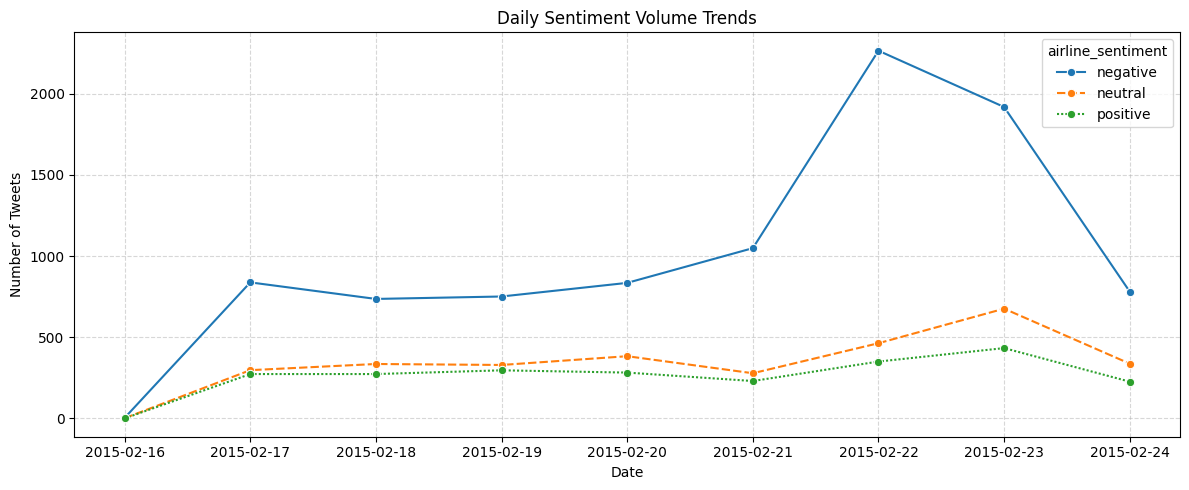

In [31]:
# Convert tweet_created to datetime
df['tweet_created_dt'] = pd.to_datetime(df['tweet_created'])
df['tweet_date'] = df['tweet_created_dt'].dt.date

temporal_sentiment = pd.crosstab(df['tweet_date'], df['airline_sentiment'])

plt.figure(figsize=(12, 5))
sns.lineplot(data=temporal_sentiment, marker='o')
plt.title('Daily Sentiment Volume Trends')
plt.xlabel('Date')
plt.ylabel('Number of Tweets')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [34]:
# Prioritization logic
def calculate_urgency_score(row):
    score = 0
    # Only prioritize negative tweets
    if row['airline_sentiment'] != 'negative':
        return 0

    # 1. Base urgency if it's a known negative issue
    score += 10 * row['airline_sentiment_confidence']

    # 2. Add weight for severe operational issues (e.g., Lost Luggage, Cancelled flights are high urgency)
    high_priority_complaints = ['Lost Luggage', 'Cancelled Flight', 'Late Flight']
    if row['negativereason'] in high_priority_complaints:
        score += 15

    # 3. Amplify based on virality / exposure (retweets)
    score += row['retweet_count'] * 5

    return score

df['urgency_score'] = df.apply(calculate_urgency_score, axis=1)
priority_queue = df[df['airline_sentiment'] == 'negative'].sort_values(by='urgency_score', ascending=False)

print("=== Top 10 High Urgency Triage Queue ===")
display(priority_queue[['airline', 'negativereason', 'retweet_count', 'text', 'urgency_score']].head(10))

=== Top 10 High Urgency Triage Queue ===


,airline,negativereason,retweet_count,text,urgency_score
11596,US Airways,Late Flight,44,@USAirways 5 hr flight delay and a delay when ...,245.000
11582,US Airways,Can't Tell,32,@USAirways of course never again tho . Thanks ...,170.000
7132,Delta,Can't Tell,31,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY....,165.000
7115,Delta,Can't Tell,22,can you not? RT @JetBlue Our fleet's on fleek....,116.940
7027,Delta,Can't Tell,18,"Just in case you needed confirmation that ""on ...",96.541
12680,American,Cancelled Flight,5,@AmericanAir Cancelled Flight my flight saying...,50.000
12681,American,Cancelled Flight,4,@AmericanAir Again you guys are a huge joke an...,45.000
12678,American,Cancelled Flight,4,@AmericanAir This is getting a bit ridiculous ...,45.000
11591,US Airways,Late Flight,4,@USAirways No need for apologies just an unfor...,41.625
4144,United,Flight Booking Problems,7,@united But I got a bad exchange rate so want ...,41.600
